<a href="https://colab.research.google.com/github/AKookani/BrickwallCliffordCircuit/blob/main/Stabilizer_Explanation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stabilizer Formalism & Clifford Circuits

In [ ]:
!pip install qiskit ipywidgets
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 43.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 1.3 MB/s eta 0:00:00


## Pauli Stablizer State

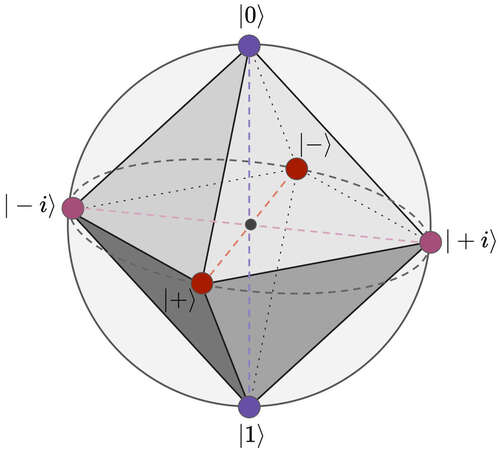



*   **Stabilizers** are **operators** that remain quantum states unchanged, i.e. the eigenvalue of the states will be $\lambda = 1$. $$\hat{M}|\psi⟩=|\psi⟩$$
*   **Stabilizer States** are quantum states that can be stabilized by Pauli operators.
*   **Generators** are **Pauli operators** that stabilze the **stabilizer states**.



### Stabilizer State of $|+\rangle$ $\leftrightsquigarrow
$ Generators of $|+⟩$

In [ ]:
from qiskit.quantum_info import StabilizerState, Statevector, SparsePauliOp

stabilizer_state = StabilizerState.from_stabilizer_list(["+X"]) #returns the state is stabilized by Z operator
print(stabilizer_state)

StabilizerState(['+X'])


⭐**Stabilizer group $(S)$** for an $\mathcal{n}$-qubit system $|\Psi⟩=|\psi⟩^{⨂n}$ are  Pauli strings $\mathcal{P}_N$ that stabilize the state.

$$\mathcal{P}_N = \left\{\bigotimes_{j=1}^n \sigma_{i_j} \; : \; i_j \in \{0,1,2,3\} \right\}$$

$$S = \left\{ \hat{P}_n \in \pm\mathcal{P}_N \; \middle| \; \hat{P}_n |\Psi\rangle = |\Psi\rangle \right\}$$

⭐**Generators** $(\mathcal{G})$ of an $n$-qubit pure stabilizer state form a set of $n$ independent stabilizers in the stabilizer group $S$, whose products generate the entire group$\langle\mathcal{G}\rangle=S$.

$$\mathcal{G}=\left\{\{g_1,\ldots,g_n\}\subseteq S \; \middle| \; \prod_{i=1}^{n}g_i^{a_i} = I^{\otimes n} \Longrightarrow a_1 = \dots = a_n = 0 :\; a_i\in\{0, 1\}\right\}$$

There are only $n$ Generators since:
$$$$

Clifford: Stabilizer = ['+X'], Destabilizer = ['+Z']


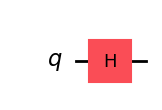

<IPython.core.display.Latex object>

In [ ]:
print(stabilizer_state.clifford)
Clifford_circuit = stabilizer_state.clifford.to_circuit()
display(Clifford_circuit.draw('mpl'))
psi = Statevector.from_instruction(Clifford_circuit)
display(psi.draw('latex'))

In [ ]:
# The 6 possible single-qubit stabilizer generators
stabilizers = ['+Z', '-Z', '+X', '-X', '+Y', '-Y']

print(f"{'Stabilizer':<12} | {'Destabilizer'}")
print("-" * 30)
for stab in stabilizers:
    state = StabilizerState.from_stabilizer_list([stab])
    # In Qiskit, mode='D' retrieves the destabilizers
    destab_list = state.clifford.to_labels(mode='D')
    print(f"{stab:<12} | {destab_list[0]}")

Stabilizer   | Destabilizer
------------------------------
+Z           | +X
-Z           | +X
+X           | +Z
-X           | +Z
+Y           | -X
-Y           | -X


`.clifford` yields the state's **Stabilizers** and **Destabilizers**, forming its **Clifford tableau**

**Clifford Tableau**:


$$\boxed{
\begin{array}{c|c|c|c}  
& X(q_0)\cdots X(q_{n-1}) & Z(q_0)\cdots Z(q_{n-1}) & \text{Phase} \\
\hline
S_0 & x_{S_0} & z_{S_0} & r_{S_0} \\
\vdots & \vdots & \vdots & \vdots \\
S_{n-1} & x_{S_{n-1}} & z_{S_{n-1}} & r_{S_{n-1}} \\
\hline
D_0 & x_{D_0} & z_{D_0} & r_{D_0} \\
\vdots & \vdots & \vdots & \vdots \\
D_{n-1} & x_{D_{n-1}} & z_{D_{n-1}} & r_{D_{n-1}}
\end{array}
}$$

⚠️ Strictly saying, the above rows of the Clifford tableau aren't the whole stabilizers, they are generators. So the word Stabilizer and generator can be used interchangeably.


❗Tracking the evolution of a quantum system, We store the **Clifford tableau**, since its each part is useful considering:


*   **Generators** $\mathcal{G} = (r_{S}) (S)$  evolve over the unitary $U$ by:
$$\mathcal{G} \xrightarrow{\text{Update}}U\mathcal{G}U^{†}$$
where $U$ is a **Clifford**.
*   **Destabilizers** pinpoint which stabilizers **anti-commute** in case of **mid-circuit** measurements.



**Mid-circuit Measurement**



*   **Case A (Deterministic):** $(Z_{i})$ **commutes** with all stabilizers **regardless** of their **phase**. The outcome is fixed by the state $S'=S$.

*   **Case B (Random):** $(Z_{i})$ **anti-commutes** with at least one stabilizer. The measurement changes the state, and the tableau gets updated.
    1.  In case of more than one anti-commutative stabilizers, multiply them two by two and replace them in one of their row of the tableau:
        $$S_i \leftarrow (S_i)(S_j)$$
        this removes the excessive anti-commutative stabilizers.

        ❗ **If two operators both anti-commute with a third operator, their product will commute with it.**
        $$\(\{A,C\}=0\) , \(\{B,C\}=0\) ⇒ \[AB,C]=0\$$

    2.  Assign `0` or `1` by 50% probability to the phase column as the output and replace the measurement stabilizer to the one remaining anti-commutative stabilizer.





### Bell state (from the circuit)

$$|\Phi^+⟩=\frac{|00\rangle + |11\rangle}{\sqrt2}$$


$\hat{XX}, \hat{ZZ}$ are generators $\mathcal{G}$ from the **Stabilizer Group** $S$.

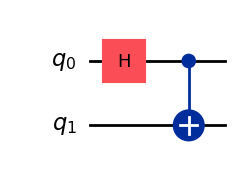

StabilizerState(['+XX', '+ZZ'])


In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import StabilizerState, Clifford

qc = QuantumCircuit(2)
cliff = []
cliff.append(Clifford(qc))
#qc.x(0)
#cliff.append(Clifford(qc))
qc.h(0)
cliff.append(Clifford(qc))
qc.cx(0, 1)
cliff.append(Clifford(qc))
display(qc.draw('mpl'))

state = StabilizerState(qc)
print(state)

In [ ]:
import pandas as pd
from IPython.display import display, Latex

for j in range (len(cliff)):
  num_qubits = cliff[j].num_qubits

  # Define row labels (Destabilizers then Stabilizers)
  row_labels = [f"Stabilizer(Q{i})" for i in range(num_qubits)] + \
              [f"Destabilizer(Q{i})" for i in range(num_qubits)]

  # Define column labels (X components, Z components, and Phase)
  col_labels = [f"X(Q{i})" for i in range(num_qubits)] + \
              [f"Z(Q{i})" for i in range(num_qubits)] + \
              ["Phase"]

  # Create a clean, labeled DataFrame
  df = pd.DataFrame(cliff[j].tableau, index=row_labels, columns=col_labels)
  # Convert the entire boolean DataFrame to 0 and 1
  styled_df = df.astype(int)
  # Optional: Map the Phase column to '+' and '-' instead of 1 and 0
  styled_df['Phase'] = df['Phase'].map({False: '+', True: '-'})
  print(styled_df)
  if j < len(cliff) - 1:
    display(Latex(r'$\hspace*{4.935cm} \parallel$'))
    display(Latex(r'$\hspace*{5cm} \blacktriangledown$'))

                  X(Q0)  X(Q1)  Z(Q0)  Z(Q1) Phase
Stabilizer(Q0)        1      0      0      0     +
Stabilizer(Q1)        0      1      0      0     +
Destabilizer(Q0)      0      0      1      0     +
Destabilizer(Q1)      0      0      0      1     +


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

                  X(Q0)  X(Q1)  Z(Q0)  Z(Q1) Phase
Stabilizer(Q0)        0      0      1      0     +
Stabilizer(Q1)        0      1      0      0     +
Destabilizer(Q0)      1      0      0      0     +
Destabilizer(Q1)      0      0      0      1     +


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

                  X(Q0)  X(Q1)  Z(Q0)  Z(Q1) Phase
Stabilizer(Q0)        0      0      1      0     +
Stabilizer(Q1)        0      1      0      0     +
Destabilizer(Q0)      1      1      0      0     +
Destabilizer(Q1)      0      0      1      1     +


## Stabilizer State Efficiency

**Clifford**

`StabilizerState` works with **Clifford gates**, which are:

* H
* S
* X, Y, Z
* CNOT (CX)
* SWAP

Non-Clifford gates are `T`, `CCX`, or arbitrary rotations such as `RX`, `RY`, `RZ` with angles except multiples of $\frac{\pi}{2}$.

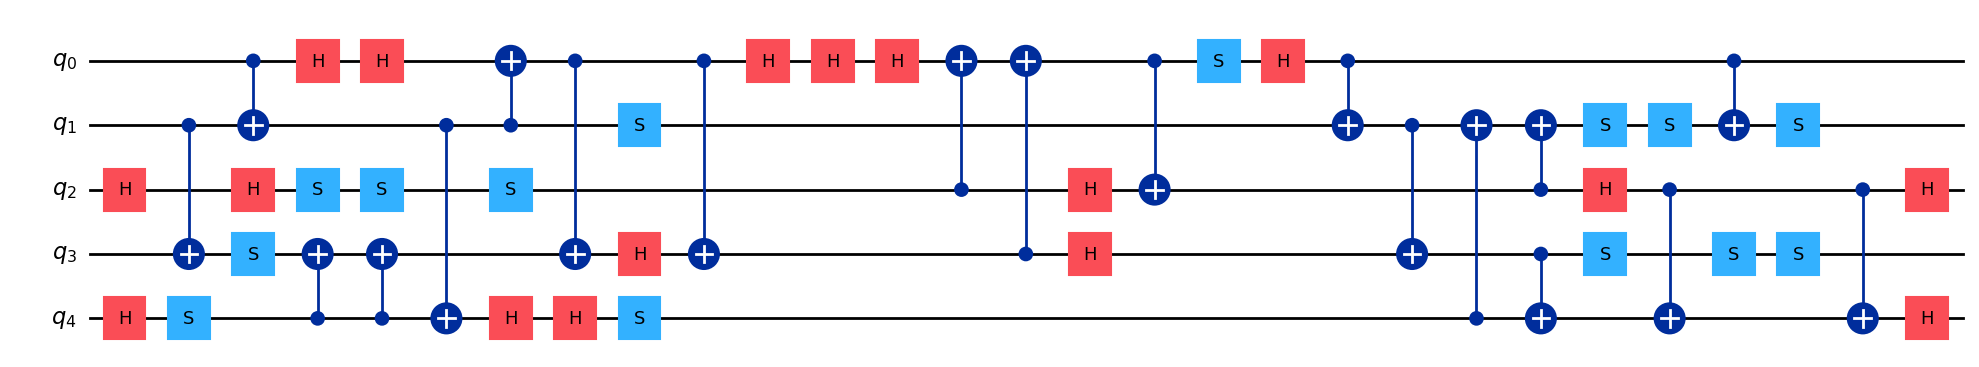

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import StabilizerState
import random

n = 5
qc = QuantumCircuit(n)

for _ in range(50):
    gate = random.choice(["h", "s", "cx"])

    if gate == "h":
        qc.h(random.randrange(n))

    elif gate == "s":
        qc.s(random.randrange(n))

    else:
        a, b = random.sample(range(n), 2)
        qc.cx(a, b)

display(qc.draw('mpl', fold=-1))

In [ ]:
stab = StabilizerState(qc)

print(stab) #There will be 5 generators because we have 5 qubits.

StabilizerState(['-YXYXY', '+ZYXYY', '-IIXYI', '-YYYXX', '-YZZXI'])


In [ ]:
from qiskit.quantum_info import Statevector

psi = Statevector.from_instruction(qc)

psi.draw('latex')

<IPython.core.display.Latex object>